# Forecasting Life Expectancy at Birth, 2011–2023

**Objective.** Forecast country-level life expectancy at birth using only information available up to and including **2010**, then compare against the observed values.

**Timing convention.** The brief says "2010 to 2023". 2010 is the last observed year (the forecast origin); scored predictions cover **2011–2023** (13 horizons).

**Models compared**

| Model | Role |
|---|---|
| Persistence | Floor: nothing changes after 2010 |
| Drift | Strong naive baseline: last value + 10-year average annual gain |
| ARIMA(1,1,0) + drift | Classical univariate time-series benchmark |
| Gradient boosting, direct multi-horizon (predicts change from 2010) | Main ML model, trained with (a) life-expectancy features only and (b) all indicators (fertility, death rate, gender gap), so the value of the other World Bank datasets is measured directly |

**Key results (2011–2023 holdout, 217 countries, 2,821 country-years; figures from the executed run below)**

| | MAE (years) | MAE excl. 2020–2022 |
|---|---|---|
| ML, life-expectancy features only | 1.00 | 0.77 |
| ML, all indicators | 1.01 | 0.80 |
| ARIMA(1,1,0) + drift | 1.53 | 1.20 |
| Drift (10-year) | 1.56 | 1.21 |
| Persistence | 1.85 | 1.73 |

- The ML model reduces MAE by about 36% relative to drift and 46% relative to persistence.
- Fertility, death rate and gender gap add no measurable accuracy over life-expectancy history alone.
- Rolling-origin validation on 1995, 2000 and 2005 origins (ending by 2010) gives the same ranking, with a smaller margin over drift.
- The largest errors come from shocks no pre-2010 model can anticipate (COVID-19, conflict, epidemics, the 2010 Haiti earthquake).

## 1. Setup and data

In [1]:
from pathlib import Path
import sys, warnings

current_path = Path.cwd()
if not (current_path / "src").exists():
    current_path = current_path.parent
PROJECT_ROOT = current_path
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
from IPython.display import display
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor
from statsmodels.tsa.arima.model import ARIMA

from src.data import build_dataset
from src.config import FORECAST_CUTOFF

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.2f}".format)

CUTOFF = FORECAST_CUTOFF            # 2010: last observed year
END_YEAR = 2023
N_H = END_YEAR - CUTOFF             # 13 forecast horizons

In [2]:
df = build_dataset()
country_df = df.loc[df["observation_type"] == "Country"].copy()

def find_col(*keywords, exclude=()):
    for c in country_df.columns:
        n = c.lower()
        if all(k in n for k in keywords) and not any(e in n for e in exclude):
            return c
    return None

# Locate indicator columns by name so the notebook does not depend on exact labels
cols = {
    "le":    "life_expectancy_total",
    "le_m":  find_col("life", "male", exclude=("female",)),
    "le_f":  find_col("life", "female"),
    "fert":  find_col("fertility"),
    "death": find_col("death"),
}
print({k: v for k, v in cols.items()})
assert cols["le"] in country_df.columns
cols = {k: v for k, v in cols.items() if v is not None}

Loading existing processed dataset.
{'le': 'life_expectancy_total', 'le_m': 'life_expectancy_male', 'le_f': 'life_expectancy_female', 'fert': 'fertility_rate', 'death': 'death_rate'}


### Leakage control and missing-data policy

- `raw` retains the original annual observations through 2023. Post-2010 values are used only as evaluation ground truth.
- `hist` is a convenience view truncated at the 2010 forecast cutoff.
- **Training features are constructed separately for each historical origin year T.** The series is first truncated at T, and only then are short internal gaps interpolated. This prevents a feature at an earlier origin from using an observation that occurs after that origin.
- Training labels use the original observed life-expectancy values at T and T+h. Missing target labels are not interpolated.
- For the final 2010 forecast, features use only data available through 2010.

This is stricter than simply truncating all series at 2010: a 1990 training example must not use information from 1991, even though 1991 is before the final 2010 cutoff.

In [3]:
years = range(1960, END_YEAR + 1)

raw = {
    k: country_df.pivot(index="year", columns="country_code", values=c).reindex(years)
    for k, c in cols.items()
}

# Cutoff-limited view for final-origin forecasts and ARIMA.
# Historical ML training features are built origin-by-origin below.
hist = {
    k: v.loc[:CUTOFF].interpolate(limit=3, limit_area="inside")
    for k, v in raw.items()
}

print(
    f"Countries: {raw['le'].shape[1]} | "
    f"Observed years: {raw['le'].index.min()}–{raw['le'].index.max()}"
)
print(
    "Countries with missing life expectancy at 2010:",
    int(hist["le"].loc[CUTOFF].isna().sum())
)

Countries: 217 | Observed years: 1960–2023
Countries with missing life expectancy at 2010: 0


## 2. Direct multi-horizon ML design

For every origin year *T* and horizon *h* we predict the **change** `LE(T+h) − LE(T)` from features known at *T*:

- level and 5 / 10-year slope of life expectancy
- female–male life-expectancy gap
- fertility rate and its 5-year change
- crude death rate and its 5-year change
- the horizon *h*

Training pairs satisfy `T + h ≤ 2010`, so no post-cutoff information is used. Predicting the change (rather than the level) lets a tree model extrapolate beyond the range seen in training, and the direct approach avoids the error accumulation of recursive forecasting.

In [4]:
def features(T):
    # Truncate first, then interpolate. No observation after T can enter these features.
    origin_hist = {
        k: v.loc[:T].interpolate(limit=3, limit_area="inside")
        for k, v in raw.items()
    }

    le = origin_hist["le"]
    X = pd.DataFrame({
        "le": le.loc[T],
        "le_slope5": (le.loc[T] - le.loc[T - 5]) / 5,
        "le_slope10": (le.loc[T] - le.loc[T - 10]) / 10,
    })

    if "le_m" in origin_hist and "le_f" in origin_hist:
        X["gender_gap"] = (
            origin_hist["le_f"].loc[T] - origin_hist["le_m"].loc[T]
        )

    if "fert" in origin_hist:
        X["fertility"] = origin_hist["fert"].loc[T]
        X["fertility_chg5"] = (
            origin_hist["fert"].loc[T] - origin_hist["fert"].loc[T - 5]
        )

    if "death" in origin_hist:
        X["death_rate"] = origin_hist["death"].loc[T]
        X["death_chg5"] = (
            origin_hist["death"].loc[T] - origin_hist["death"].loc[T - 5]
        )

    X.index.name = "country_code"
    return X


LE_ONLY = ["le", "le_slope5", "le_slope10"]
FULL = list(features(CUTOFF).columns)

rows = []
for T in range(1970, CUTOFF):
    X = features(T)

    # Labels come from original observations, not interpolated feature histories.
    for h in range(1, min(N_H, CUTOFF - T) + 1):
        y_change = raw["le"].loc[T + h] - raw["le"].loc[T]

        d = X.copy()
        d["h"] = h
        d["origin"] = T
        d["y"] = y_change
        rows.append(d)

panel = pd.concat(rows).dropna(subset=LE_ONLY + ["y"]).reset_index()
print(
    f"Training pairs: {len(panel):,} | "
    f"origins {panel.origin.min()}–{panel.origin.max()} | "
    f"max target year {(panel.origin + panel.h).max()}"
)
assert (panel.origin + panel.h).max() <= CUTOFF

Training pairs: 95,514 | origins 1970–2009 | max target year 2010


In [5]:
def fit_hgb(feature_cols):
    # Fixed, conservative settings. Not tuned on 2011–2023.
    model = HistGradientBoostingRegressor(
        max_depth=4,
        learning_rate=0.05,
        max_iter=300,
        min_samples_leaf=50,
        l2_regularization=1.0,
        random_state=42,
    )

    # HistGradientBoostingRegressor can handle missing feature values.
    model.fit(panel[feature_cols + ["h"]], panel["y"])
    return model


hgb_le = fit_hgb(LE_ONLY)
hgb_full = fit_hgb(FULL)

print("Life-expectancy-only features:", LE_ONLY)
print("All-indicator features:", FULL)

Life-expectancy-only features: ['le', 'le_slope5', 'le_slope10']
All-indicator features: ['le', 'le_slope5', 'le_slope10', 'gender_gap', 'fertility', 'fertility_chg5', 'death_rate', 'death_chg5']


## 3. Rolling-origin validation (within the pre-2011 period)

The single 2010-origin evaluation answers how well the models forecast 2011–2023 from 2010. It does not show whether the approach is stable across different historical forecast origins.

We therefore use expanding-window rolling-origin validation with three non-overlapping five-year validation windows:

- Origin 1995: forecast 1996–2000
- Origin 2000: forecast 2001–2005
- Origin 2005: forecast 2006–2010

At each fold, the training set includes only supervised examples whose target year is no later than that fold's origin. Features are reconstructed using information available at each historical origin. The 2011–2023 final test period is not used for validation or model selection.

We compare persistence, drift, and both gradient-boosting feature sets. ARIMA is evaluated only on the final 2010 origin: per-country ARIMA refits for every fold add cost without changing the question this section answers, which is whether the ML design and its feature sets are stable across origins.

Hyperparameters are fixed in advance, so this section is a stability check rather than a tuning exercise.

In [6]:
VALIDATION_ORIGINS = [1995, 2000, 2005]
VALIDATION_HORIZON = 5

rolling_rows = []

for validation_origin in VALIDATION_ORIGINS:
        # Keep only training examples whose outcomes were observable
        # by the validation origin.
        fold_train = panel.loc[
            panel["origin"] + panel["h"] <= validation_origin
        ].copy()

        # Construct validation features using information available
        # only through this fold's origin.
        fold_X = features(validation_origin).dropna(subset=LE_ONLY)

        # Generate one row per country and validation horizon.
        fold_test = pd.concat(
            [
                fold_X.assign(h=h)
                for h in range(1, VALIDATION_HORIZON + 1)
            ]
        ).reset_index()

        fold_test["origin"] = validation_origin
        fold_test["year"] = validation_origin + fold_test["h"]

        # Actual outcomes are used only as validation labels.
        fold_test["actual_at_horizon"] = [
            raw["le"].loc[row.year, row.country_code]
            for row in fold_test.itertuples()
        ]

        # Baseline predictions.
        fold_test["persistence"] = fold_test["le"]
        fold_test["drift"] = (
            fold_test["le"] + fold_test["le_slope10"] * fold_test["h"]
        )

        # Train each ML model using only data available at this fold.
        fold_models = {}

        for model_name, feature_cols in [
            ("ml_le_only", LE_ONLY),
            ("ml_full", FULL)
        ]:
            usable_train = fold_train.dropna(
                subset=LE_ONLY + ["h", "y"]
            )

            fold_model = HistGradientBoostingRegressor(
                max_depth=4,
                learning_rate=0.05,
                max_iter=300,
                min_samples_leaf=50,
                l2_regularization=1.0,
                random_state=42,
            )

            fold_model.fit(
                usable_train[feature_cols + ["h"]],
                usable_train["y"]
            )

            # Predict change from the fold's origin, then add the origin level.
            fold_test[model_name] = (
                fold_test["le"]
                + fold_model.predict(fold_test[feature_cols + ["h"]])
            )

            fold_models[model_name] = fold_model

        # Keep only country-horizon rows with an observed actual value
        # and all four model predictions.
        prediction_cols = [
            "persistence", "drift", "ml_le_only", "ml_full"
        ]

        fold_eval = fold_test.dropna(
            subset=["actual_at_horizon"] + prediction_cols
        ).copy()

        fold_eval["validation_origin"] = validation_origin
        rolling_rows.append(fold_eval)

        print(
            f"Origin {validation_origin}: "
            f"training pairs={len(fold_train):,}, "
            f"validation rows={len(fold_eval):,}, "
            f"countries={fold_eval['country_code'].nunique()}"
        )

rolling_evaluation = pd.concat(rolling_rows, ignore_index=True)

print("\nTotal rolling-origin validation observations:",
      f"{len(rolling_evaluation):,}")
print("Validation origins:",
      sorted(rolling_evaluation["validation_origin"].unique()))

Origin 1995: training pairs=53,339, validation rows=1,080, countries=216
Origin 2000: training pairs=67,379, validation rows=1,085, countries=217
Origin 2005: training pairs=81,434, validation rows=1,085, countries=217

Total rolling-origin validation observations: 3,250
Validation origins: [np.int64(1995), np.int64(2000), np.int64(2005)]


### Rolling-origin validation results

We calculate MAE and RMSE across all validation folds. Each row is a country-origin-horizon prediction. These validation metrics are used to assess model stability and compare feature sets; they are not the final 2011–2023 test metrics.

In [7]:
ROLLING_MODELS = {
    "Persistence": "persistence",
    "Drift (10y)": "drift",
    "ML, LE features only": "ml_le_only",
    "ML, all indicators": "ml_full",
}

rolling_summary = []

for name, prediction_col in ROLLING_MODELS.items():
    errors = (
        rolling_evaluation["actual_at_horizon"]
        - rolling_evaluation[prediction_col]
    )

    rolling_summary.append({
        "Model": name,
        "MAE": errors.abs().mean(),
        "RMSE": np.sqrt((errors ** 2).mean()),
        "Bias": -errors.mean(),
    })

rolling_summary = (
    pd.DataFrame(rolling_summary)
    .set_index("Model")
    .sort_values("MAE")
)

rolling_summary["Skill vs persistence"] = (
    1 - rolling_summary["MAE"]
    / rolling_summary.loc["Persistence", "MAE"]
)

display(rolling_summary.round(3))

,MAE,RMSE,Bias,Skill vs persistence
Model,,,,
"ML, LE features only",0.67,1.45,-0.14,0.38
"ML, all indicators",0.68,1.41,-0.09,0.38
Drift (10y),0.73,1.57,-0.12,0.33
Persistence,1.09,1.69,-0.87,0.00


### Performance by validation origin and horizon

Aggregated results can hide instability. The next table shows whether a model performs consistently across the three historical origins and at different forecast horizons.

In [8]:
rolling_by_fold = []

for (origin, horizon), group in rolling_evaluation.groupby(
    ["validation_origin", "h"]
):
    row = {
        "Origin": origin,
        "Forecast year": origin + horizon,
        "Horizon": horizon,
    }

    for name, prediction_col in ROLLING_MODELS.items():
        row[f"{name} MAE"] = (
            group["actual_at_horizon"] - group[prediction_col]
        ).abs().mean()

    rolling_by_fold.append(row)

rolling_by_fold = pd.DataFrame(rolling_by_fold)
display(rolling_by_fold.round(2))

,Origin,Forecast year,Horizon,Persistence MAE,Drift (10y) MAE,"ML, LE features only MAE","ML, all indicators MAE"
0,1995,1996,1,0.39,0.30,0.40,0.41
1,1995,1997,2,0.74,0.53,0.58,0.53
2,1995,1998,3,1.05,0.84,0.86,0.78
3,1995,1999,4,1.43,1.13,1.08,1.02
4,1995,2000,5,1.77,1.26,1.21,1.13
5,2000,2001,1,0.43,0.25,0.35,0.40
6,2000,2002,2,0.76,0.46,0.47,0.50
7,2000,2003,3,1.12,0.74,0.71,0.70
8,2000,2004,4,1.50,0.98,0.88,0.87
9,2000,2005,5,1.78,1.14,0.99,1.01


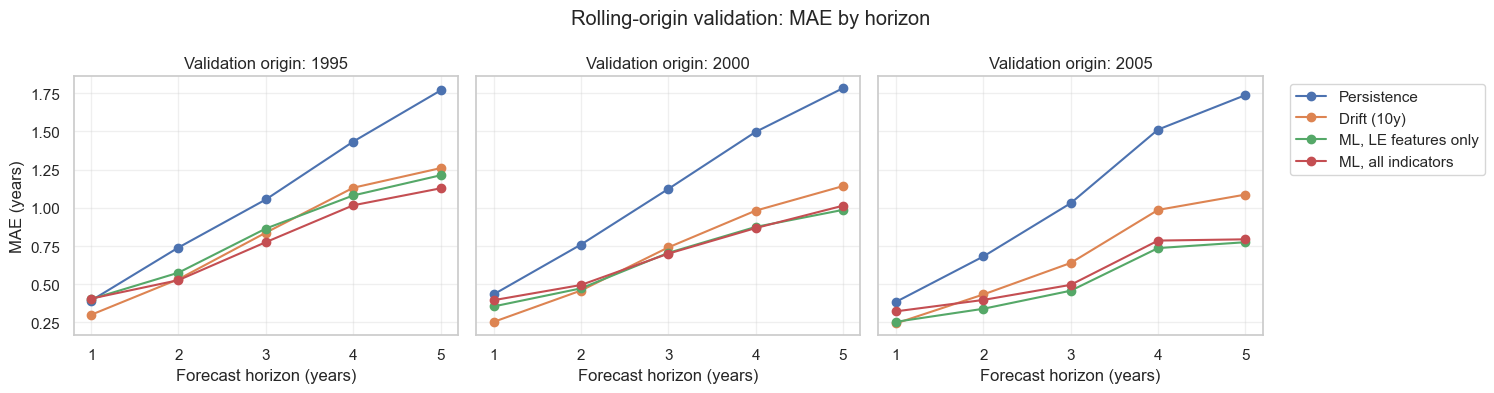

In [9]:
rolling_plot = (
    rolling_evaluation
    .groupby(["validation_origin", "h"])
    .apply(
        lambda g: pd.Series({
            name: (
                g["actual_at_horizon"] - g[prediction_col]
            ).abs().mean()
            for name, prediction_col in ROLLING_MODELS.items()
        }),
        include_groups=False
    )
    .reset_index()
)

fig, axes = plt.subplots(
    1, len(VALIDATION_ORIGINS),
    figsize=(15, 4),
    sharey=True
)

for ax, origin in zip(axes, VALIDATION_ORIGINS):
    fold_plot = rolling_plot[
        rolling_plot["validation_origin"] == origin
    ]

    for name in ROLLING_MODELS:
        ax.plot(
            fold_plot["h"],
            fold_plot[name],
            marker="o",
            label=name
        )

    ax.set_title(f"Validation origin: {origin}")
    ax.set_xlabel("Forecast horizon (years)")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("MAE (years)")
axes[-1].legend(bbox_to_anchor=(1.05, 1), loc="upper left")
fig.suptitle("Rolling-origin validation: MAE by horizon")
plt.tight_layout()
plt.show()

### Rolling-origin findings

- **Aggregate:** the two ML models (MAE 0.67 and 0.68) outperform drift (0.73) and persistence (1.09). The margin over drift is modest.
- **Horizon dependence:** drift is as good as or better than the life-expectancy-only ML model at 1–2 year horizons in the 1995 and 2000 folds, and level with it at 1 year in the 2005 fold. The ML advantage is clearer at longer horizons (from about 4 years in the earlier folds, from 2 years in 2005), for example at 5 years: 0.78 vs 1.09 (2005 fold), 0.99 vs 1.14 (2000), 1.21 vs 1.26 (1995).
- **Feature sets:** the all-indicator model is slightly better in the 1995 fold but no better in the 2000 and 2005 folds, so the additional indicators do not help consistently.
- **Consequence for the final test:** the ML model is the primary candidate, with the expectation that its advantage is concentrated at longer horizons. The 2011–2023 period was not used for validation or model selection.

## 4. Final forecasts from the 2010 origin

In [10]:
# Build the 2010-origin feature set. Only countries with the required LE features
# are eligible for the ML forecasts.
X0 = features(CUTOFF).dropna(subset=LE_ONLY)

test = pd.concat(
    [X0.assign(h=h) for h in range(1, N_H + 1)]
).reset_index()

test["year"] = CUTOFF + test["h"]

# Baselines
test["persistence"] = test["le"]
test["drift"] = test["le"] + test["le_slope10"] * test["h"]

# Direct multi-horizon ML: predict change from the 2010 level.
test["ml_le_only"] = (
    test["le"] + hgb_le.predict(test[LE_ONLY + ["h"]])
)
test["ml_full"] = (
    test["le"] + hgb_full.predict(test[FULL + ["h"]])
)

# ARIMA(1,1,0) with drift, fitted separately for each country.
# Preserve the annual index and retain missing years rather than dropping them
# and accidentally treating non-consecutive years as consecutive observations.
arima_rows = []
arima_failures = []

for cc in hist["le"].columns:
    s = hist["le"][cc].copy()
    s.index = pd.PeriodIndex(s.index.astype(int), freq="Y")

    origin_period = pd.Period(str(CUTOFF), freq="Y")
    if s.notna().sum() < 20 or pd.isna(s.loc[origin_period]):
        arima_failures.append({
            "country_code": cc,
            "reason": "Fewer than 20 observed/interpolated values or missing 2010 origin"
        })
        continue

    try:
        fitted = ARIMA(
            s,
            order=(1, 1, 0),
            trend="t",
            missing="none"
        ).fit()

        forecast = fitted.forecast(N_H)

        arima_rows.extend([
            {
                "country_code": cc,
                "year": CUTOFF + i + 1,
                "arima": float(value)
            }
            for i, value in enumerate(forecast)
        ])

    except Exception as exc:
        arima_failures.append({
            "country_code": cc,
            "reason": str(exc)
        })

arima_predictions = pd.DataFrame(arima_rows)
arima_failures = pd.DataFrame(arima_failures)

test = test.merge(
    arima_predictions,
    on=["country_code", "year"],
    how="left"
)

# Ground truth is attached only after all forecasts have been generated.
actual = (
    raw["le"].loc[CUTOFF + 1:END_YEAR]
    .rename_axis(index="year")
    .reset_index()
    .melt(
        id_vars="year",
        var_name="country_code",
        value_name="actual"
    )
)

ev = test.merge(actual, on=["country_code", "year"], how="left")

country_names = (
    country_df[["country_code", "country"]]
    .drop_duplicates()
)
ev = ev.merge(country_names, on="country_code", how="left")

MODELS = {
    "Persistence": "persistence",
    "Drift (10y)": "drift",
    "ARIMA(1,1,0)+drift": "arima",
    "ML, LE features only": "ml_le_only",
    "ML, all indicators": "ml_full",
}

cohort = ev.dropna(subset=["actual"] + list(MODELS.values())).copy()

print(f"Countries in source dataset: {country_df['country_code'].nunique()}")
print(f"Countries with valid 2010 ML origin: {X0.shape[0]}")
print(f"Countries with ARIMA forecasts: {arima_predictions['country_code'].nunique()}")
print(f"Countries in common evaluation cohort: {cohort['country_code'].nunique()}")
print(f"Common evaluation set: {len(cohort):,} country-years")
print(f"Forecast years: {cohort['year'].min()}–{cohort['year'].max()}")
print(f"Countries excluded from ARIMA: {len(arima_failures)}")

if not arima_failures.empty:
    display(arima_failures.head(20))

Countries in source dataset: 217
Countries with valid 2010 ML origin: 217
Countries with ARIMA forecasts: 217
Countries in common evaluation cohort: 217
Common evaluation set: 2,821 country-years
Forecast years: 2011–2023
Countries excluded from ARIMA: 0


### Evaluation cohort

A common cohort ensures every model is scored on the same country-year observations. Coverage counts are reported below.

In [11]:
coverage = pd.DataFrame({
    "Measure": [
        "Countries in source dataset",
        "Countries with valid 2010 ML origin",
        "Countries with ARIMA forecasts",
        "Countries in common evaluation cohort",
        "Country-year observations in common cohort",
        "Countries excluded from ARIMA"
    ],
    "Count": [
        country_df["country_code"].nunique(),
        X0.shape[0],
        arima_predictions["country_code"].nunique(),
        cohort["country_code"].nunique(),
        len(cohort),
        len(arima_failures)
    ]
})
display(coverage)

,Measure,Count
0,Countries in source dataset,217
1,Countries with valid 2010 ML origin,217
2,Countries with ARIMA forecasts,217
3,Countries in common evaluation cohort,217
4,Country-year observations in common cohort,2821
5,Countries excluded from ARIMA,0


## 5. Results

Metrics are computed on one common set of country-years (see the evaluation cohort above). **Bias** is the mean of forecast minus actual (negative means under-forecasting). **Skill** is `1 − MAE / MAE_persistence` (positive means better than assuming no change). Pooled R² is not reported: between-country variation dominates, so it is high for every model, including persistence, and does not discriminate between them.

In [12]:
def score_table(d):
    out = {}
    for name, c in MODELS.items():
        e = d["actual"] - d[c]
        out[name] = {"MAE": e.abs().mean(), "RMSE": np.sqrt((e**2).mean()), "Bias": -e.mean()}
    t = pd.DataFrame(out).T
    t["Skill vs persistence"] = 1 - t["MAE"] / t.loc["Persistence", "MAE"]
    return t.sort_values("MAE")

print("All years 2011–2023")
display(score_table(cohort))

print("Excluding 2020–2022 (COVID-19 shock)")
display(score_table(cohort[~cohort.year.between(2020, 2022)]))

All years 2011–2023


,MAE,RMSE,Bias,Skill vs persistence
"ML, LE features only",1.00,1.90,0.39,0.46
"ML, all indicators",1.01,1.90,0.34,0.45
"ARIMA(1,1,0)+drift",1.53,2.77,0.69,0.17
Drift (10y),1.56,3.15,0.67,0.16
Persistence,1.85,2.90,-1.55,0.00


Excluding 2020–2022 (COVID-19 shock)


,MAE,RMSE,Bias,Skill vs persistence
"ML, LE features only",0.77,1.67,0.14,0.55
"ML, all indicators",0.80,1.68,0.09,0.54
"ARIMA(1,1,0)+drift",1.20,2.55,0.34,0.31
Drift (10y),1.21,2.80,0.33,0.30
Persistence,1.73,2.76,-1.51,0.00


,Persistence,Drift (10y),"ARIMA(1,1,0)+drift","ML, LE features only","ML, all indicators"
year,,,,,
2011,0.54,0.38,0.49,0.32,0.35
2012,0.78,0.48,0.45,0.35,0.38
2013,1.09,0.65,0.72,0.46,0.47
2014,1.42,0.90,0.83,0.62,0.65
2015,1.64,1.12,1.16,0.75,0.78
2016,1.87,1.28,1.27,0.84,0.86
2017,2.08,1.46,1.45,0.95,0.97
2018,2.24,1.53,1.52,0.94,0.96
2019,2.47,1.73,1.61,1.07,1.09


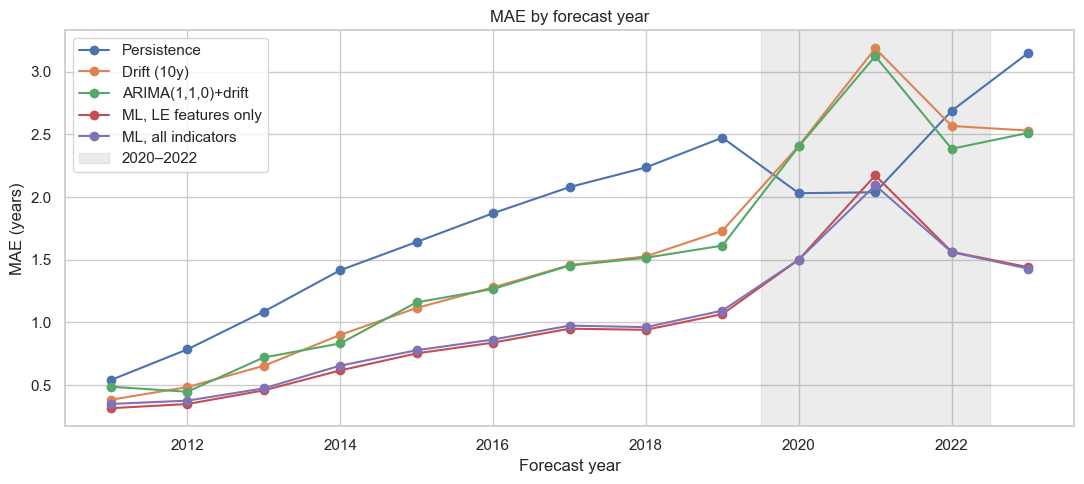

In [13]:
yearly = cohort.groupby("year").apply(
    lambda g: pd.Series({
        name: (g["actual"] - g[column]).abs().mean()
        for name, column in MODELS.items()
    }),
    include_groups=False,
)

display(yearly.round(2))

ax = yearly.plot(marker="o", figsize=(11, 5))
ax.axvspan(2019.5, 2022.5, color="grey", alpha=0.15, label="2020–2022")
ax.set(
    title="MAE by forecast year",
    xlabel="Forecast year",
    ylabel="MAE (years)"
)
ax.legend()
plt.tight_layout()
plt.show()

### Where the models fail

Country-level MAE highlights where each model has the largest errors. Observations are left unaltered: the largest errors coincide with documented events (conflict in South Sudan, Syria and the Central African Republic, the 2010 Haiti earthquake) rather than visible data defects.

In [14]:
cty = cohort.groupby(["country_code", "country"]).apply(
    lambda g: pd.Series({
        name: (g["actual"] - g[column]).abs().mean()
        for name, column in MODELS.items()
    }),
    include_groups=False,
).reset_index()

res = score_table(cohort)
best = res.index[0]

print(f"Countries with the largest errors for {best}")
display(
    cty.sort_values(best, ascending=False)
    .head(10)
    .round(2)
)

Countries with the largest errors for ML, LE features only


,country_code,country,Persistence,Drift (10y),"ARIMA(1,1,0)+drift","ML, LE features only","ML, all indicators"
177,SSD,South Sudan,6.27,12.78,9.97,10.04,10.37
31,CAF,Central African Republic,7.49,7.48,17.30,7.69,7.53
186,SYR,Syrian Arab Republic,5.02,6.90,8.00,6.33,6.32
175,SOM,"Somalia, Fed. Rep.",6.72,7.98,5.91,6.15,6.13
183,SWZ,Eswatini,8.43,7.94,3.78,5.02,4.37
216,ZWE,Zimbabwe,7.46,3.34,5.57,3.48,2.99
85,HTI,Haiti,17.77,26.59,12.85,3.06,2.20
214,ZAF,South Africa,5.17,4.80,3.69,2.38,1.95
141,NER,Niger,2.23,3.30,1.20,2.10,2.57
139,NAM,Namibia,5.23,3.03,3.54,2.08,2.59


### Robustness: median error

MAE is sensitive to a few extreme countries (for example Haiti, where the 2010 origin value distorts drift and ARIMA). The median absolute error shows the typical country.

In [15]:
def median_ae(d):
    return pd.Series({
        name: (d["actual"] - d[c]).abs().median()
        for name, c in MODELS.items()
    })

median_table = pd.DataFrame({
    "All years": median_ae(cohort),
    "Excl. 2020–2022": median_ae(cohort[~cohort.year.between(2020, 2022)]),
}).sort_values("All years")

display(median_table.round(2))

,All years,Excl. 2020–2022
"ML, LE features only",0.54,0.42
"ML, all indicators",0.54,0.43
Drift (10y),0.75,0.55
"ARIMA(1,1,0)+drift",0.83,0.62
Persistence,1.25,1.14


### Reading the results

- **ML vs baselines:** the life-expectancy-only ML model has the lowest MAE in every forecast year except 2021, where persistence (2.04) edges it (2.17). Before 2020 its advantage over drift widens with horizon; in 2020–2021 drift and ARIMA are hit hardest because they extrapolate pre-2020 gains into the COVID years.
- **Drift vs ARIMA:** the two are close on MAE (1.56 vs 1.53), which is expected because ARIMA(1,1,0) with a trend is largely a drift model. ARIMA is slightly worse for the typical country (median error 0.83 vs 0.75) and edges drift on MAE only through a few outliers.
- **COVID-19:** excluding 2020–2022 lowers every model's MAE (ML 1.00 → 0.77) but leaves the ranking unchanged.
- **Failure cases:** persistence and drift are most distorted in Haiti (MAE 17.8 and 26.6); the ML model is far more robust there (3.1). South Sudan, the Central African Republic, Syria and Somalia remain difficult for all models.
- **Typical country vs outliers:** the median absolute error is 0.54 years for the ML model versus 0.75 for drift (28% lower) and 1.25 for persistence. The ML advantage over drift is smaller at the median than at the mean (36%), so part of the MAE gain comes from robustness in outlier countries, but it holds for the typical country as well. The ranking is unchanged excluding 2020–2022 (0.42 vs 0.55).

## 6. Contribution of additional indicators

Compare the ML model using life-expectancy history alone with the model using all indicators on the common cohort.

In [16]:
ml_feature_comparison = score_table(cohort).loc[
    ["ML, LE features only", "ML, all indicators"]
]
display(ml_feature_comparison.round(3))

le_mae = ml_feature_comparison.loc["ML, LE features only", "MAE"]
full_mae = ml_feature_comparison.loc["ML, all indicators", "MAE"]
change = le_mae - full_mae

if change > 0:
    print(f"Adding the additional indicators reduces MAE by {change:.3f} years.")
elif change < 0:
    print(f"Adding the additional indicators increases MAE by {abs(change):.3f} years.")
else:
    print("The two ML feature sets have identical MAE on this cohort.")

,MAE,RMSE,Bias,Skill vs persistence
"ML, LE features only",1.00,1.90,0.39,0.46
"ML, all indicators",1.01,1.90,0.34,0.46


Adding the additional indicators increases MAE by 0.011 years.


## 7. Conclusions, limitations and next steps

**Conclusion.** A direct multi-horizon gradient-boosting model that predicts the change from the 2010 level reaches an MAE of 1.00 years on 2011–2023 (0.77 excluding 2020–2022), versus 1.56 for drift and 1.85 for persistence. Fertility, death rate and gender gap did not improve accuracy, so the simpler life-expectancy-only model is the recommended choice.

**Method choices.**
- *Direct, not recursive:* each horizon is predicted straight from 2010-era information, so errors do not compound.
- *Target is change:* avoids the tree-model inability to extrapolate beyond training levels.
- *Hyperparameters fixed in advance*, not tuned on 2011–2023, so the test period stays a clean holdout.
- *Drift as the real benchmark:* life expectancy trends steadily, so beating persistence alone is not informative.
- *Origin-by-origin feature construction:* historical training features are rebuilt at each origin year, so interpolation cannot use observations after that origin; missing target labels are not interpolated.
- *Common cohort:* all metrics are computed on the same country-years, with coverage reported separately.

**Limitations.**
- **Unforecastable shocks:** COVID-19 (2020–2022), conflicts and epidemics (Syria, Central African Republic, South Sudan) dominate the largest errors. No model using pre-2010 data can anticipate them.
- **Shock-contaminated origin:** a single anomalous 2010 value (Haiti earthquake) corrupts level-based and slope-based baselines. The ML model is largely robust to it, but a robust origin value (for example a 2008–2010 median) is a possible refinement.
- **Training-period regimes:** the 1990s Rwanda collapse and the southern-Africa HIV era distort learned relationships.
- **Fixed-horizon training data:** long horizons (h = 13) are trained only on origins up to 1997, so the long-range model sees fewer and older examples.
- **Limited origin diversity:** rolling-origin validation covers three origins, all ending by 2010; robustness to post-2010 regimes is only observed on the single holdout.
- **No uncertainty quantification:** only point forecasts are evaluated.

**Next steps.**
- Blend drift and ML at short horizons, where drift is competitive.
- Quantile gradient boosting or conformal intervals, with coverage checks.
- Robust origin level and outlier-aware slopes.
- Additional pre-2010 covariates (income, health expenditure, education, HIV prevalence).
- Hyperparameter selection by rolling-origin validation within the pre-2011 window.